[![Open in molab](https://marimo.io/molab-shield.svg)](https://molab.marimo.io/github/adriansousapoza/tgmm/blob/main/notebooks/15_covariance_models.py)

# Covariance Structures: From Full Matrices to the 14 GPCM Models

Every component of a Gaussian mixture owns a covariance matrix $\Sigma_k$, and it is by far the
most expensive and most consequential part of the model: a full covariance in $d$ dimensions has
$d(d+1)/2$ free parameters per component, so a mixture can easily spend more parameters describing
the *shapes* of its clusters than their locations. `covariance_type` controls how much freedom each
$\Sigma_k$ gets, and with it the trade-off between flexibility (can the model follow
elongated, rotated clusters?) and parsimony (can it be estimated reliably from limited data?).

`tgmm` offers two layers of choices. The six **classic** types (`'full'`, `'diag'`, `'spherical'`
and their `tied_` versions) are the ones scikit-learn offers. On top of them, `GaussianMixture`
supports all 14 **Gaussian Parsimonious Clustering Models** (GPCM) of Celeux & Govaert (1995) --
the family `mclust` implements -- which write each covariance as a product of a *volume*, a *shape*
and an *orientation* and let you share or free each factor independently.

This notebook shows what each choice looks like, derives **how EM estimates every one of them**
(the M-step), checks the derivations numerically against the library, and uses BIC to select among
all 14 models on real data.

**What you'll learn**

- how the covariance enters EM's M-step, and why every covariance type is the same optimisation
  problem over a different feasible set;
- the closed-form estimates for the six classic types, and their number of free parameters;
- the volume / shape / orientation decomposition behind the 14 GPCM models and its mclust naming;
- how each of the 14 models is estimated: closed forms, alternating updates, and the one step
  that needs a numerical (Stiefel-manifold) optimisation;
- how to read `volume_`, `shape_`, `orientation_` on a fitted model, and how to select a covariance
  structure with `select_model`.

**Prerequisites:** [01 -- Gaussian Mixture Models](01_gmm.ipynb) and
[02 -- The EM Algorithm](02_em_algorithm.ipynb) (the E-step / M-step vocabulary).
See also the [GPCM user guide](../user-guide/gpcm-covariance-models.md) for a reference summary.

## Setup

Run this notebook from the `notebooks/` directory; the first line of the next cell moves to the
repository root so `import tgmm` resolves to the local checkout.

In [ ]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

from tgmm import GaussianMixture, select_model, generate_gmm_data
from tgmm.covariance.gpcm import GPCM_CODES, mstep_gpcm
from tgmm.plotting import plot_gmm, dynamic_figsize

device = 'cuda' if torch.cuda.is_available() else 'cpu'
plt.rcParams['figure.dpi'] = 100  # tgmm's theme uses 300 dpi; marimo embeds figures at 2x, so keep outputs small
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
print(f'Using device: {device}')

Using device: cpu


## A dataset whose clusters have different covariance structures

Four clusters in two dimensions, each with a deliberately different covariance: two spherical ones
of different size, one axis-aligned elongated one, and one tilted (correlated) one. This is the same
dataset as in the [first tutorial](01_gmm.ipynb), which makes it a good test bed: *no single
simple covariance type describes all four clusters*.

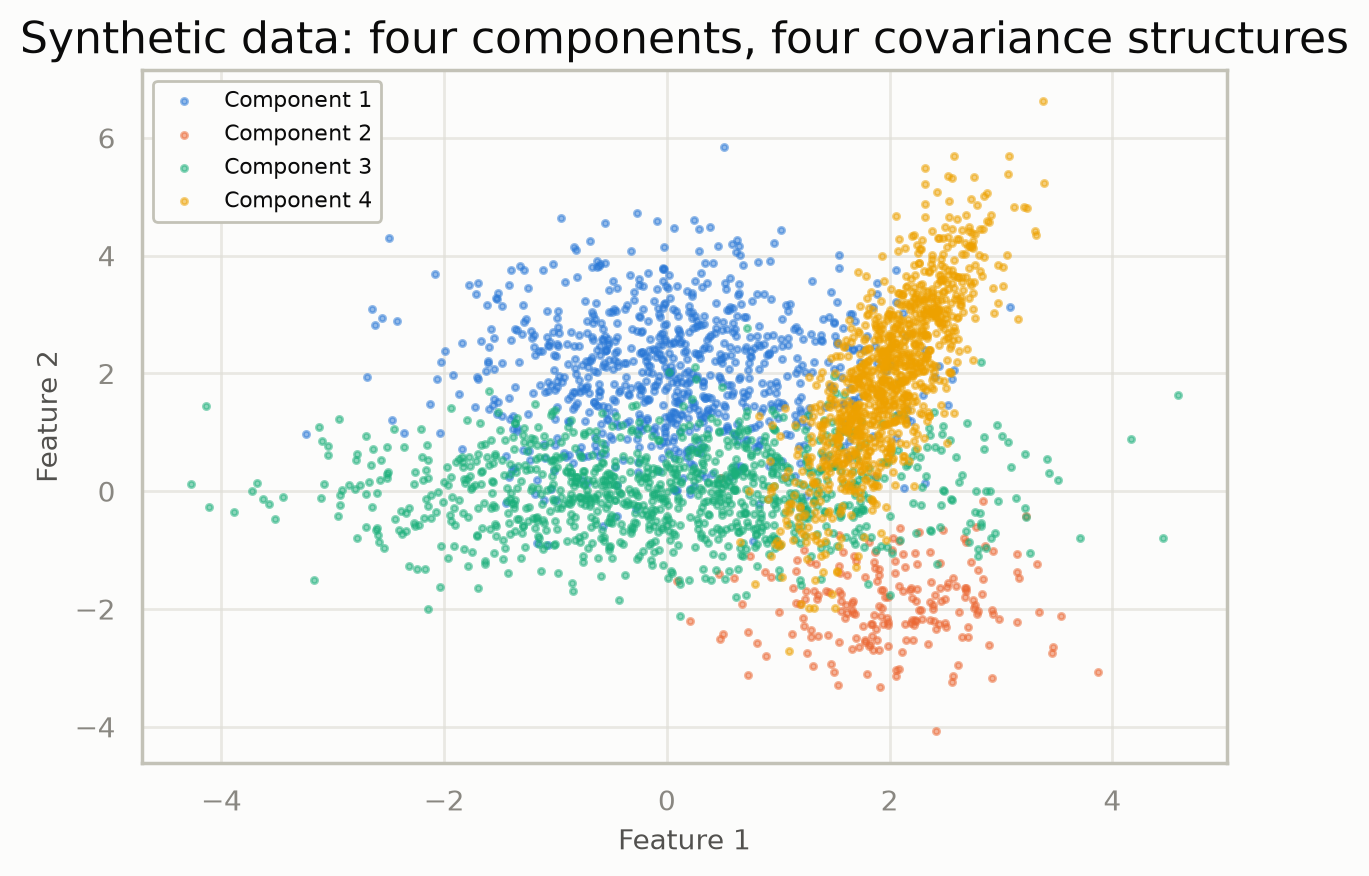

In [ ]:
n_samples = [800, 200, 1000, 1000]
centers = [np.array([0, 2]),
           np.array([2, -2]),
           np.array([0, 0]),
           np.array([2, 2])]
covs = [
    1.0 * np.eye(2),                    # spherical
    0.5 * np.eye(2),                    # spherical, smaller and with fewer points
    np.array([[2, 0], [0, 0.5]]),       # diagonal (axis-aligned, elongated)
    np.array([[0.2, 0.5], [0.5, 2]]),   # full (tilted, correlated)
]

X, y_true = generate_gmm_data(centers, covs, n_samples, device=device, random_state=SEED)
X = X.double()  # float64: the numerical checks below compare against closed forms to ~1e-6
n, d = X.shape
K = len(n_samples)
legend_labels = [f'Component {k + 1}' for k in range(K)]

plot_gmm(X=X.cpu().numpy(), true_labels=y_true.cpu().numpy(),
         title='Synthetic data: four components, four covariance structures',
         legend_labels=legend_labels)
plt.gcf()

## The six classic covariance types

Each type constrains the matrices $\Sigma_1,\dots,\Sigma_K$ differently. A covariance is *tied* if
all components share it, *spherical* if it is a multiple of the identity, *diagonal* if it is
axis-aligned, and *full* otherwise:

| `covariance_type` | constraint | free covariance parameters |
| --- | --- | --- |
| `'tied_spherical'` | $\Sigma_k = \sigma^2 I$ for all $k$ | $1$ |
| `'spherical'` | $\Sigma_k = \sigma_k^2 I$ | $K$ |
| `'tied_diag'` | $\Sigma_k = \mathrm{diag}(\sigma_1^2,\dots,\sigma_d^2)$ for all $k$ | $d$ |
| `'diag'` | $\Sigma_k = \mathrm{diag}(\sigma_{k1}^2,\dots,\sigma_{kd}^2)$ | $Kd$ |
| `'tied_full'` | $\Sigma_k = \Sigma$ for all $k$, any symmetric positive-definite matrix | $d(d+1)/2$ |
| `'full'` | each $\Sigma_k$ any symmetric positive-definite matrix | $K\,d(d+1)/2$ |

The grid below fits each one to the dataset above. The ellipses are the fitted components' 1-,
2- and 3-standard-deviation contours: spherical types can only draw circles, diagonal types only
axis-aligned ellipses, tied types give every component the *same* ellipse, and only `'full'` can
follow the tilted cluster *and* give each cluster its own size.

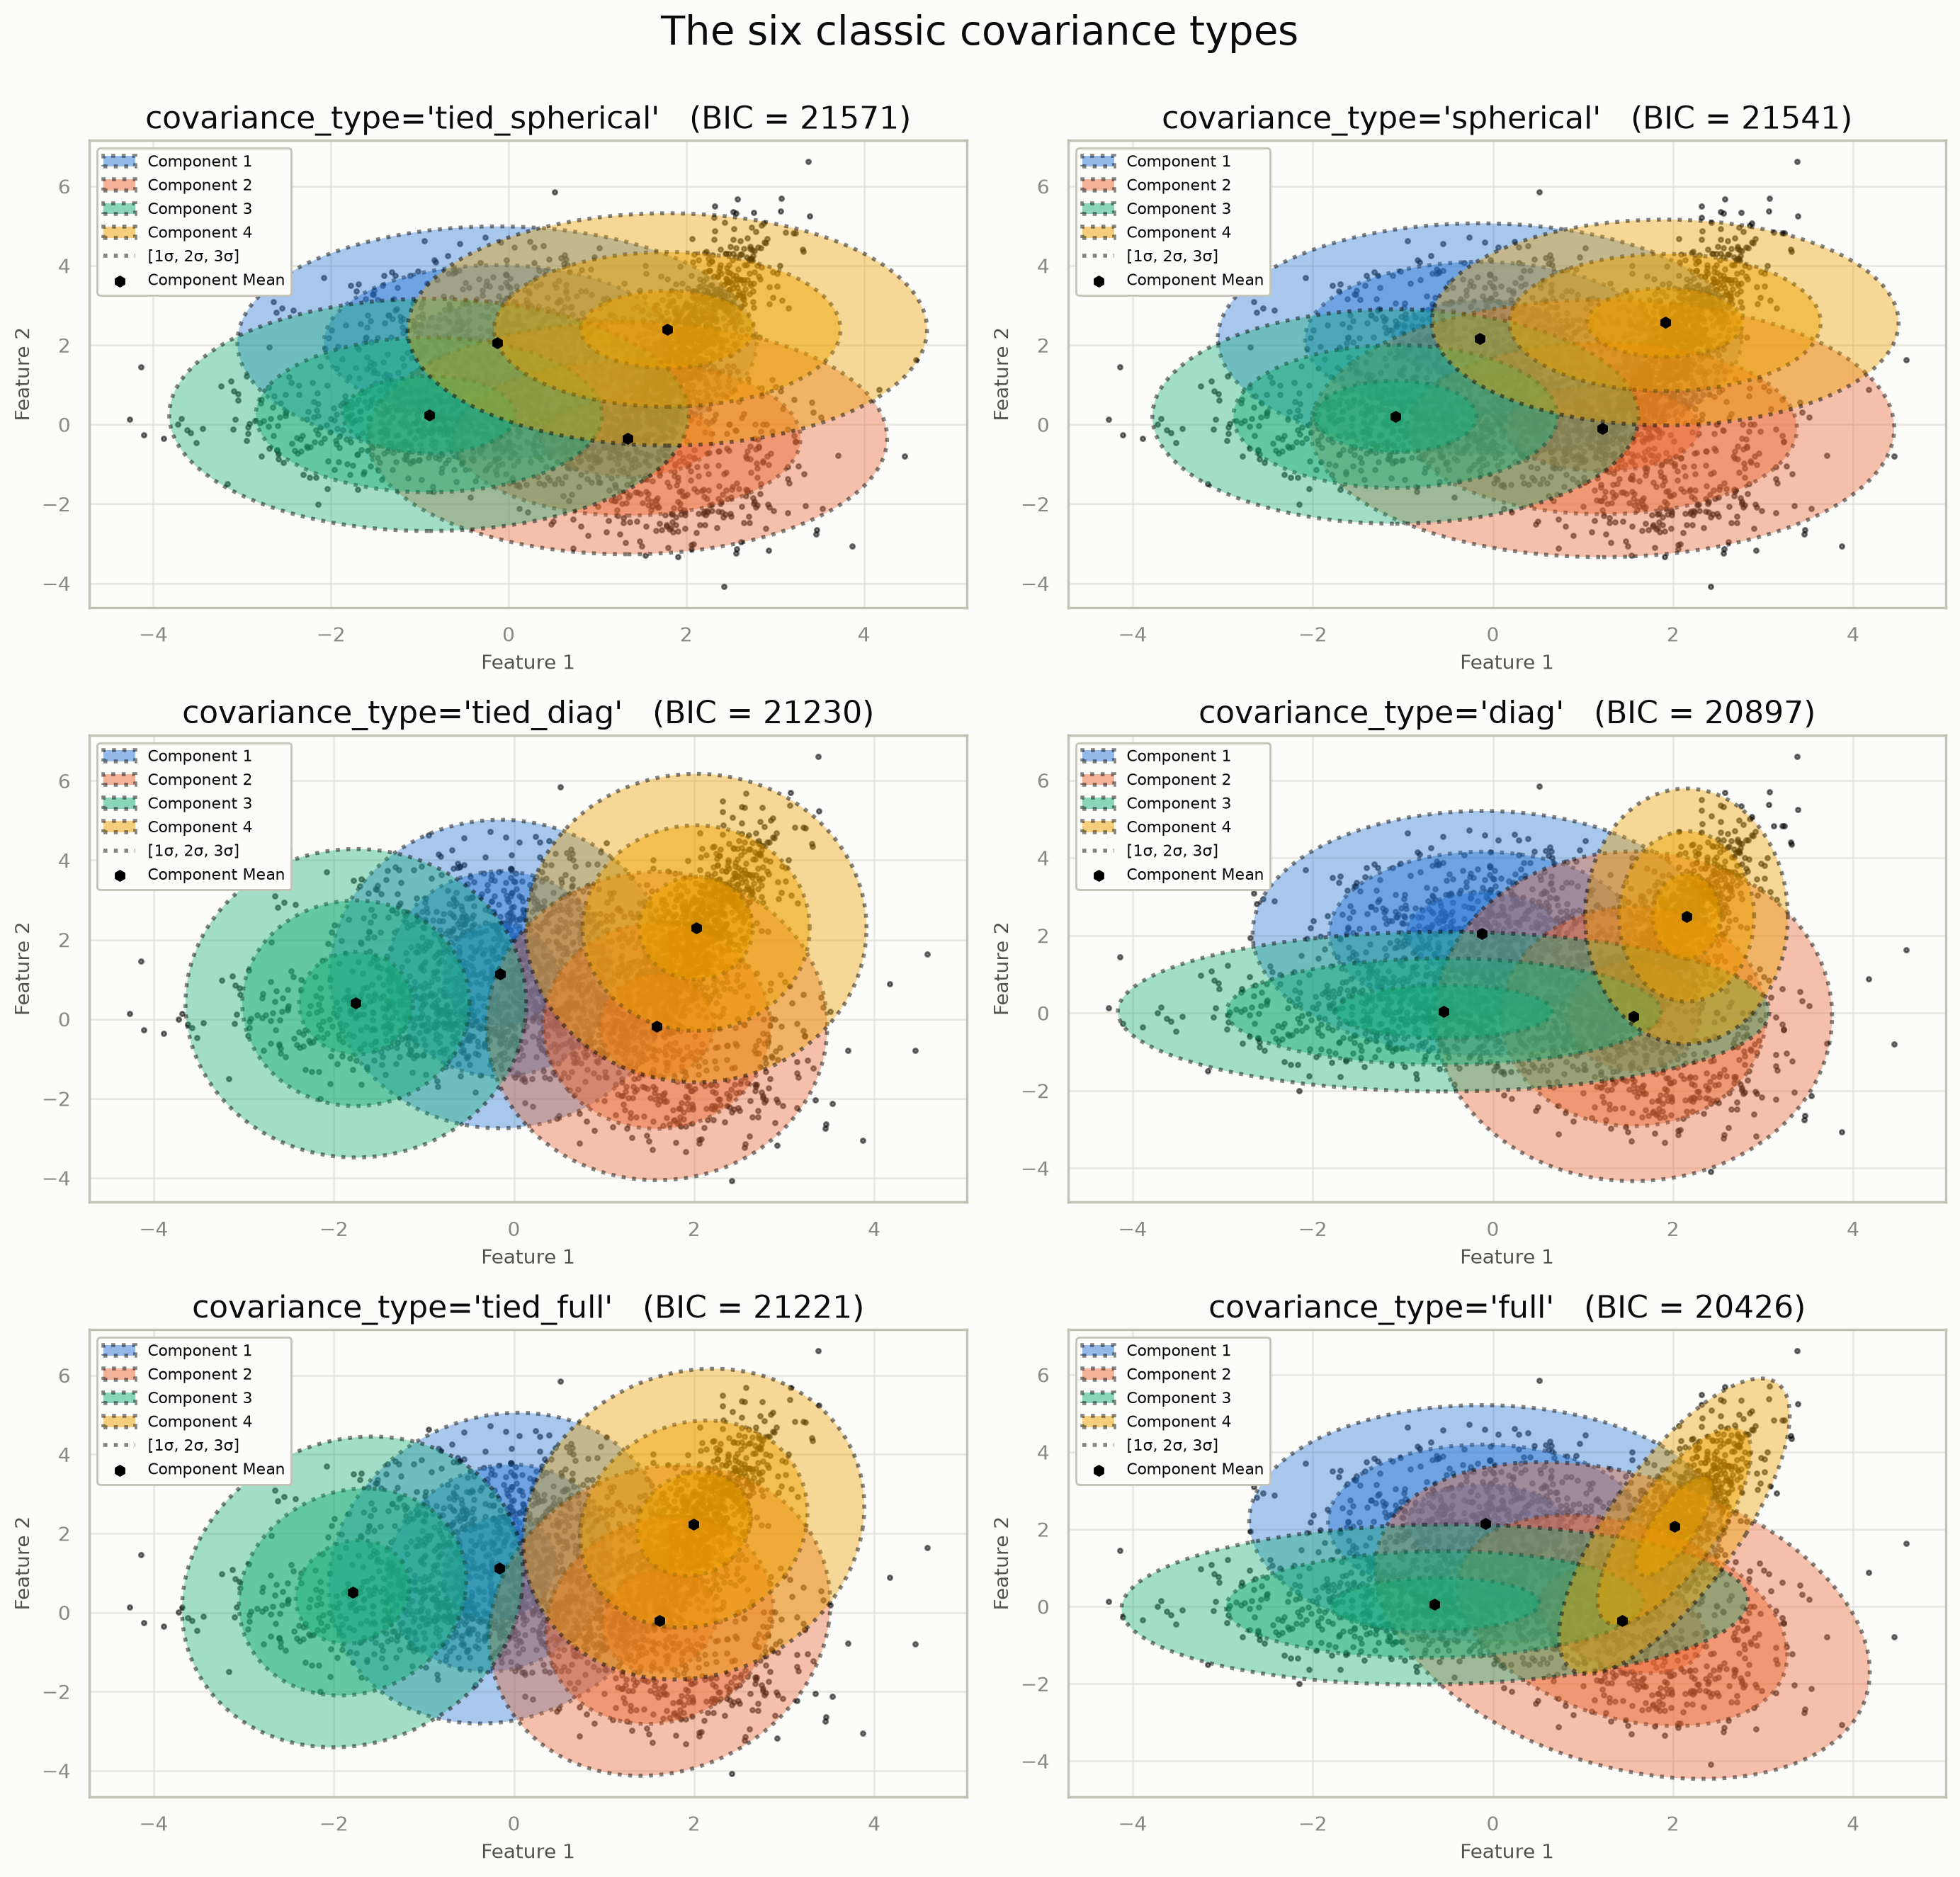

In [ ]:
classic_types = ['tied_spherical', 'spherical', 'tied_diag', 'diag', 'tied_full', 'full']
_fig, _axs = plt.subplots(3, 2, figsize=dynamic_figsize(3, 2), dpi=100)
for _ax, _cov_type in zip(_axs.ravel(), classic_types):
    _gmm = GaussianMixture(n_components=K, covariance_type=_cov_type, init_means='kmeans', random_state=SEED, device=device)
    _gmm.fit(X)
    plot_gmm(X.cpu().numpy(), gmm=_gmm, ax=_ax, legend_labels=legend_labels, title=f"covariance_type='{_cov_type}'   (BIC = {_gmm.bic(X):.0f})")
plt.suptitle('The six classic covariance types')
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.gcf()

## How EM estimates a covariance: the M-step

Given the responsibilities $r_{ik}$ from the E-step (the posterior probability that point $x_i$
came from component $k$), the M-step maximises the expected complete-data log-likelihood

$$
Q(\theta)=\sum_{i=1}^{n}\sum_{k=1}^{K} r_{ik}\Big[\log\pi_k-\tfrac d2\log 2\pi-\tfrac12\log|\Sigma_k|
-\tfrac12 (x_i-\mu_k)^{\top}\Sigma_k^{-1}(x_i-\mu_k)\Big].
$$

Write $n_k=\sum_i r_{ik}$ for the effective number of points in component $k$. Maximising over
$\mu_k$ gives the responsibility-weighted mean $\bar y_k=\frac1{n_k}\sum_i r_{ik}x_i$. Since

$$
\sum_i r_{ik}(x_i-\mu_k)^{\top}\Sigma_k^{-1}(x_i-\mu_k)
=\mathrm{tr}\Big(\Sigma_k^{-1}\sum_i r_{ik}(x_i-\mu_k)(x_i-\mu_k)^{\top}\Big),
$$

and at $\mu_k=\bar y_k$ the inner sum is the **weighted scatter matrix**

$$
W_k=\sum_{i=1}^{n} r_{ik}\,(x_i-\bar y_k)(x_i-\bar y_k)^{\top},
$$

the only part of $Q$ that depends on the covariances is, up to a constant factor $-\tfrac12$,

$$
\boxed{\;J(\Sigma_1,\dots,\Sigma_K)=\sum_{k=1}^{K}\Big[\,n_k\log|\Sigma_k|+\mathrm{tr}\big(\Sigma_k^{-1}W_k\big)\Big]\;}
\qquad\text{(to be minimised).}
$$

This is the key fact of the whole notebook: **every covariance type is the same objective $J$
minimised over a different feasible set.** The M-step needs the data only through $(n_k, W_k)$ --
these are exactly the sufficient statistics `tgmm` accumulates (`SufficientStats.nk` and `.s2`) --
and the covariance types differ only in which matrices $\Sigma_k$ they allow. (`reg_covar` is
added to the diagonal of the result afterwards, to keep matrices positive definite; the formulas
below are the unregularised solutions.)

### The six classic closed forms

Substituting $\Omega_k=\Sigma_k^{-1}$, the full-covariance term is
$J_k=-n_k\log|\Omega_k|+\mathrm{tr}(\Omega_kW_k)$, whose gradient $-n_k\Omega_k^{-1}+W_k$ vanishes at
$\Sigma_k=W_k/n_k$. The constrained types follow by restricting the feasible set:

- **Diagonal**, $\Sigma_k=\mathrm{diag}(\sigma_{kj}^2)$: $J$ separates over coordinates,
  $J_k=\sum_j\big[n_k\log\sigma_{kj}^2+(W_k)_{jj}/\sigma_{kj}^2\big]$, minimised at
  $\sigma_{kj}^2=(W_k)_{jj}/n_k$.
- **Spherical**, $\Sigma_k=\sigma_k^2I$: $J_k=n_kd\log\sigma_k^2+\mathrm{tr}(W_k)/\sigma_k^2$, minimised at
  $\sigma_k^2=\mathrm{tr}(W_k)/(d\,n_k)$.
- **Tied** versions: the same $\Sigma$ appears in every term, so $n_k$ and $W_k$ are simply pooled
  across components -- $n=\sum_kn_k$ and $\sum_kW_k$ take their place.

| type | estimate |
| --- | --- |
| `full` | $\Sigma_k=W_k/n_k$ |
| `diag` | $\Sigma_k=\mathrm{diag}(W_k)/n_k$ |
| `spherical` | $\Sigma_k=\dfrac{\mathrm{tr}(W_k)}{d\,n_k}\,I$ |
| `tied_full` | $\Sigma=\dfrac1n\sum_kW_k$ |
| `tied_diag` | $\Sigma=\mathrm{diag}\Big(\sum_kW_k\Big)\big/n$ |
| `tied_spherical` | $\Sigma=\dfrac{\mathrm{tr}\big(\sum_kW_k\big)}{d\,n}\,I$ |

At a converged EM fit the stored covariances must be a fixed point of these formulas applied to the
final responsibilities. The cell below checks that: it recomputes $n_k$, $\bar y_k$ and $W_k$ from
`predict_proba` and compares the closed forms with `covariances_`.

In [ ]:
def e_step_statistics(gmm, X):
    """n_k, ybar_k and the scatter matrices W_k implied by the model's responsibilities."""
    r = gmm.predict_proba(X).detach()  # (n, K)   r_ik
    nk = r.sum(dim=0)  # (K,)     n_k
    ybar = r.T @ X / nk[:, None]  # (K, d)   weighted means
    diff = X[None, :, :] - ybar[:, None, :]  # (K, n, d)
    W = torch.einsum('ik,kid,kie->kde', r, diff, diff)  # (K, d, d) scatter matrices
    return (nk, ybar, W)

def classic_mle(cov_type, nk, W):
    """The closed-form covariance estimates from the table above."""
    n, d = (nk.sum(), W.shape[-1])
    diag_W = torch.diagonal(W, dim1=-2, dim2=-1)
    return {'full': lambda: W / nk[:, None, None], 'diag': lambda: diag_W / nk[:, None], 'spherical': lambda: diag_W.sum(-1) / (nk * d), 'tied_full': lambda: W.sum(0) / n, 'tied_diag': lambda: diag_W.sum(0) / n, 'tied_spherical': lambda: diag_W.sum() / (n * d)}[cov_type]()  # (K, d)
_rows = []
for _cov_type in classic_types:
    _gmm = GaussianMixture(n_components=K, covariance_type=_cov_type, init_means='kmeans', random_state=SEED, device=device, max_iter=2000, tol=1e-12, reg_covar=0.0)
    _gmm.fit(X)
    nk, ybar, W = e_step_statistics(_gmm, X)
    gap = (_gmm.covariances_ - classic_mle(_cov_type, nk, W)).abs().max().item()
    _rows.append({'covariance_type': _cov_type, 'EM iterations': _gmm.n_iter_, 'max |covariances_ - closed form|': gap})
pd.DataFrame(_rows)  # reg_covar=0 and a tight tolerance so the fixed-point property holds to numerical precision

,covariance_type,EM iterations,max |covariances_ - closed form|
0,tied_spherical,366,1.763494e-07
1,spherical,262,8.627339e-07
2,tied_diag,152,5.015613e-07
3,diag,374,2.172464e-06
4,tied_full,213,1.541700e-07
5,full,288,1.991513e-06


The gaps are at the level of the convergence tolerance: the library's M-step *is* the table above.

## Volume, shape and orientation: the GPCM family

The six classic types are a rather coarse menu: nothing sits between "every component has its own
unconstrained matrix" and "everything is tied or axis-aligned". Banfield & Raftery (1993) and
Celeux & Govaert (1995) proposed to take apart each covariance through its eigendecomposition

$$
\boxed{\;\Sigma_k=\lambda_k\,D_k\,A_k\,D_k^{\top}\;},\qquad
\det A_k=1,\quad D_k^{\top}D_k=I,\quad A_k=\mathrm{diag}(a_{k1}\ge\dots\ge a_{kd}>0),
$$

into three geometrically meaningful pieces:

- **volume** $\lambda_k=|\Sigma_k|^{1/d}>0$ -- how large the cluster is (its ellipsoid's volume
  scales as $\lambda_k^{d/2}$);
- **shape** $A_k$ -- how elongated it is: the relative lengths of its axes (only ratios matter,
  because $\det A_k=1$ moves all the scale into $\lambda_k$);
- **orientation** $D_k$ -- which way the axes point (the columns of $D_k$ are the principal
  directions).

The semi-axes of the cluster's one-standard-deviation ellipse are $\sqrt{\lambda_k a_{kj}}$ along
the $j$-th column of $D_k$. The figure varies one factor at a time.

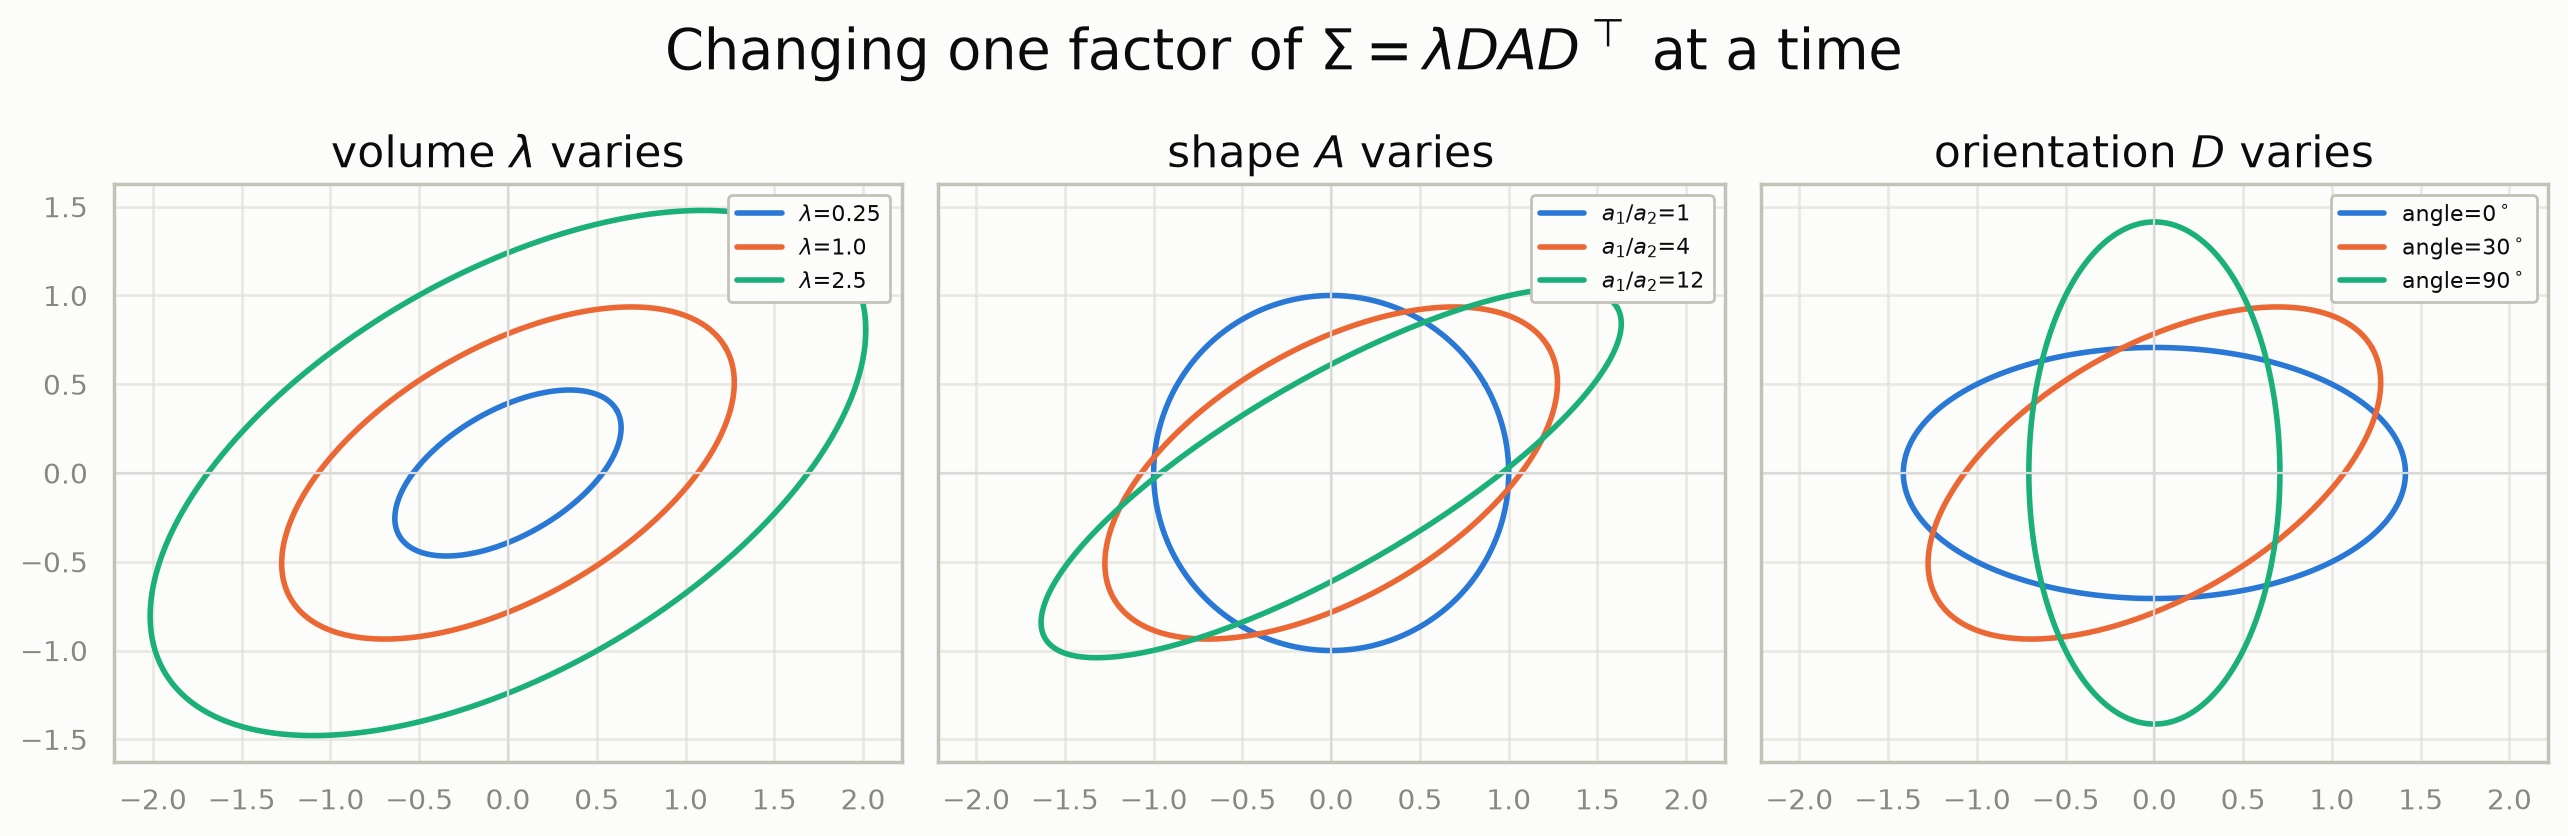

In [ ]:
def ellipse(volume, shape_diag, angle_deg, n_points=200):
    """Unit-Mahalanobis contour of Sigma = volume * D diag(shape) D^T, D = rotation by `angle`."""
    theta = np.deg2rad(angle_deg)
    D = np.array([[np.cos(theta), -np.sin(theta)], [np.sin(theta), np.cos(theta)]])
    t = np.linspace(0, 2 * np.pi, n_points)
    circle = np.stack([np.cos(t), np.sin(t)])
    return D @ np.diag(np.sqrt(volume * np.asarray(shape_diag))) @ circle

def unit_det(a, b):
    """A = diag(a, b) rescaled to determinant 1."""
    s = np.sqrt(a * b)
    return (a / s, b / s)
base = dict(volume=1.0, shape=unit_det(4.0, 1.0), angle=30)
_fig, _axs = plt.subplots(1, 3, figsize=(13, 4.2), sharex=True, sharey=True)
panels = [('volume $\\lambda$ varies', [dict(base, volume=v) for v in (0.25, 1.0, 2.5)], lambda c: f"$\\lambda$={c['volume']}"), ('shape $A$ varies', [dict(base, shape=unit_det(a, 1.0)) for a in (1.0, 4.0, 12.0)], lambda c: f"$a_1/a_2$={c['shape'][0] / c['shape'][1]:.0f}"), ('orientation $D$ varies', [dict(base, angle=a) for a in (0, 30, 90)], lambda c: f"angle={c['angle']}$^\\circ$")]
for _ax, (title, configs, label) in zip(_axs, panels):
    for cfg in configs:
        pts = ellipse(cfg['volume'], cfg['shape'], cfg['angle'])
        _ax.plot(pts[0], pts[1], label=label(cfg))
    _ax.set_title(title)
    _ax.set_aspect('equal')
    _ax.axhline(0, color='0.85', lw=0.8)
    _ax.axvline(0, color='0.85', lw=0.8)
    _ax.legend(loc='upper right', fontsize=8)
plt.suptitle('Changing one factor of $\\Sigma=\\lambda D A D^{\\top}$ at a time')
plt.tight_layout()
plt.gcf()

### The 14 models and their names

Each factor can be **E**qual across components, **V**ary from component to component, or -- for
shape and orientation only -- be the **I**dentity ($A_k=I$: spherical; $D_k=I$: axis-aligned, no
rotation). A model's mclust code reads *Volume–Shape–Orientation*, e.g. `EVE` = equal volume,
varying shape, equal orientation. Of the $2\times3\times3$ letter combinations, 14 are valid:

| code | volume | shape | orientation | `tgmm` alias | free covariance parameters |
| --- | --- | --- | --- | --- | --- |
| `EII` | equal | identity | identity | `'tied_spherical'` | $1$ |
| `VII` | varying | identity | identity | `'spherical'` | $K$ |
| `EEI` | equal | equal | identity | `'tied_diag'` | $d$ |
| `VEI` | varying | equal | identity | -- | $K+(d-1)$ |
| `EVI` | equal | varying | identity | -- | $1+K(d-1)$ |
| `VVI` | varying | varying | identity | `'diag'` | $Kd$ |
| `EEE` | equal | equal | equal | `'tied_full'` | $d(d+1)/2$ |
| `VEE` | varying | equal | equal | -- | $K+(d-1)+d(d-1)/2$ |
| `EVE` | equal | varying | equal | -- | $1+K(d-1)+d(d-1)/2$ |
| `VVE` | varying | varying | equal | -- | $Kd+d(d-1)/2$ |
| `EEV` | equal | equal | varying | -- | $d+K\,d(d-1)/2$ |
| `VEV` | varying | equal | varying | -- | $K+(d-1)+K\,d(d-1)/2$ |
| `EVV` | equal | varying | varying | -- | $1+K(d-1)+K\,d(d-1)/2$ |
| `VVV` | varying | varying | varying | `'full'` | $K\,d(d+1)/2$ |

The parameter count is simply the sum of three independent contributions:

| factor | `E` | `V` | `I` |
| --- | --- | --- | --- |
| volume | $1$ | $K$ | -- |
| shape (free ratios of $A$) | $d-1$ | $K(d-1)$ | $0$ |
| orientation (free angles of $D$) | $d(d-1)/2$ | $K\,d(d-1)/2$ | $0$ |

This count is what `bic`/`aic` charge for the covariances, so it decides which models win a
model-selection sweep. The next cell evaluates the table and checks it against the penalty that the
library actually applies, recovered from the public API: since
$\mathrm{BIC}=-2\,\ell+p\log n$ with $\ell=n\cdot$`score(X)`, the implied number of parameters is
$p=(\mathrm{BIC}+2\ell)/\log n$, to which the formula adds the $K-1$ free weights and $Kd$ means.

In [ ]:
ALIASES = {'EII': 'tied_spherical', 'VII': 'spherical', 'EEI': 'tied_diag', 'VVI': 'diag', 'EEE': 'tied_full', 'VVV': 'full'}

def n_cov_params(code, K, d):
    """Free covariance parameters of a GPCM model: volume + shape + orientation."""
    volume = {'E': 1, 'V': K}[code[0]]
    shape = {'I': 0, 'E': d - 1, 'V': K * (d - 1)}[code[1]]
    orientation = {'I': 0, 'E': d * (d - 1) // 2, 'V': K * d * (d - 1) // 2}[code[2]]
    return volume + shape + orientation
_rows = []
for _code_name in GPCM_CODES:
    _gmm = GaussianMixture(n_components=K, covariance_type=_code_name, init_means='kmeans', random_state=SEED, device=device)
    _gmm.fit(X)
    implied_total = (_gmm.bic(X) + 2 * n * _gmm.score(X)) / np.log(n)
    formula_total = n_cov_params(_code_name, K, d) + K * d + (K - 1)
    _rows.append({'code': _code_name, 'alias': ALIASES.get(_code_name, ''), f'covariance params (K={K}, d={d})': n_cov_params(_code_name, K, d), 'total (formula)': formula_total, 'total implied by bic()': round(implied_total, 6)})
df_params = pd.DataFrame(_rows)
assert np.allclose(df_params['total (formula)'], df_params['total implied by bic()'])
df_params  # = p, total parameters

,code,alias,"covariance params (K=4, d=2)",total (formula),total implied by bic()
0,EII,tied_spherical,1,12,12.0
1,VII,spherical,4,15,15.0
2,EEI,tied_diag,2,13,13.0
3,VEI,,5,16,16.0
4,EVI,,5,16,16.0
...,...,...,...,...,...
9,EEV,,6,17,17.0
10,VVE,,9,20,20.0
11,VEV,,9,20,20.0
12,EVV,,9,20,20.0


### Reading the decomposition off a fitted model

For the 8 models without a classic alias, `GaussianMixture` exposes the fitted decomposition as
`volume_`, `shape_` and `orientation_`; `covariances_` always holds the assembled
$(K, d, d)$ matrices, so everything else (`predict`, `sample`, `plot_gmm`, `save`, ...) is
oblivious to which model was used. (The six classic types do not compute a decomposition, so these
attributes are `None` for them.) Below, `EVE` -- one shared volume and one shared orientation,
but a separate shape per component -- is fitted to the data and its covariances are rebuilt from
the three factors.

In [ ]:
gmm_eve = GaussianMixture(n_components=K, covariance_type='EVE', init_means='kmeans',
                          random_state=SEED, device=device)
gmm_eve.fit(X)

print('volume_      (shared, scalar):', gmm_eve.volume_.item())
print('orientation_ (shared D):\n', gmm_eve.orientation_.cpu().numpy().round(3))
print('shape_ (one row of a_1 >= a_2 per component, each with a_1 * a_2 = 1):')
print(gmm_eve.shape_.cpu().numpy().round(3))

# Sigma_k = lambda * D diag(a_k) D^T (+ reg_covar * I), exactly as the decomposition says
D, lam = gmm_eve.orientation_, gmm_eve.volume_
rebuilt = lam * D @ torch.diag_embed(gmm_eve.shape_) @ D.T
rebuilt = rebuilt + gmm_eve.reg_covar * torch.eye(d, dtype=rebuilt.dtype, device=rebuilt.device)
print('\nmax |rebuilt - covariances_| =', (rebuilt - gmm_eve.covariances_).abs().max().item())

volume_      (shared, scalar): 0.6577851747687826
orientation_ (shared D):
 [[ 0.965  0.261]
 [-0.261  0.965]]
shape_ (one row of a_1 >= a_2 per component, each with a_1 * a_2 = 1):
[[0.872 1.147]
 [0.587 1.702]
 [1.521 0.657]
 [0.23  4.345]]

max |rebuilt - covariances_| = 4.440892098500626e-16


## Deriving the M-step for all 14 models

With the decomposition, $|\Sigma_k|=\lambda_k^d$ (because $\det D_k=\pm1$, $\det A_k=1$) and
$\Sigma_k^{-1}=\lambda_k^{-1}D_kA_k^{-1}D_k^{\top}$, so by the cyclic property of the trace

$$
J=\sum_{k=1}^{K}\Big[\,n_k\,d\,\log\lambda_k+\frac1{\lambda_k}\,\mathrm{tr}\big(A_k^{-1}D_k^{\top}W_kD_k\big)\Big].
$$

Every model fixes some of the factors to be shared or trivial; the M-step minimises $J$ over the
rest. Two small lemmas do almost all the work.

**Lemma 1 (shape).** Let $B$ be symmetric positive definite. Among positive-definite $C$ with
$\det C=1$,
$$\mathrm{tr}(C^{-1}B)\;\ge\;d\,(\det B)^{1/d},\qquad\text{with equality iff } C=B/(\det B)^{1/d}.$$
*Proof.* The eigenvalues $\mu_1,\dots,\mu_d$ of $C^{-1/2}BC^{-1/2}$ have product
$\det B/\det C=\det B$. By the AM–GM inequality
$\mathrm{tr}(C^{-1}B)=\sum_j\mu_j\ge d(\prod_j\mu_j)^{1/d}=d(\det B)^{1/d}$, with equality iff all
$\mu_j$ coincide, i.e. $B=\mu C$; $\det C=1$ then forces $\mu=(\det B)^{1/d}$. $\square$
For diagonal $C$ and diagonal $B$ this reads $a_j\propto b_j$, normalised to unit product.

**Lemma 2 (orientation).** Let $W$ be symmetric with eigenvalues $\omega_1\ge\dots\ge\omega_d$ and
let $a_1\ge\dots\ge a_d>0$. Over orthogonal $D$,
$$\mathrm{tr}\big(A^{-1}D^{\top}WD\big)\;\ge\;\sum_j\frac{\omega_j}{a_j},$$
attained when the columns of $D$ are the eigenvectors of $W$, ordered by decreasing eigenvalue.
*Proof sketch.* $\mathrm{tr}(A^{-1}D^{\top}WD)=\sum_j(D^{\top}WD)_{jj}/a_j$ and the diagonal of
$D^{\top}WD$ is majorised by $(\omega_j)$ (Schur–Horn); a linear functional with increasing weights
$1/a_j$ is smallest when the largest $\omega$ is paired with the largest $a$ (the smallest weight).
$\square$ This is why `tgmm` keeps every shape sorted in decreasing order: component $k$'s first
axis is its longest one, and orderings stay consistent when eigenvalues are summed across components.

### Group 1 -- closed forms (`EVI`, `EEV`, `EVV`, and the six classic ones)

The six classic types were solved above (they are `EII`, `VII`, `EEI`, `VVI`, `EEE`, `VVV`). Three
of the new models are also available in closed form:

- **`EVI`** ($\Sigma_k=\lambda A_k$, axis-aligned). Only the diagonal $B_k=\mathrm{diag}(W_k)$ matters
  in $\mathrm{tr}(A_k^{-1}W_k)$. For any $\lambda$, Lemma 1 gives
  $A_k=B_k/|B_k|^{1/d}$ ($|B_k|=\prod_j(W_k)_{jj}$) and $\mathrm{tr}(A_k^{-1}B_k)=d|B_k|^{1/d}$, so
  $J=nd\log\lambda+\frac d\lambda\sum_k|B_k|^{1/d}$, minimised at
  $$\lambda=\frac1n\sum_k|B_k|^{1/d}.$$
- **`EEV`** ($\Sigma_k=\lambda D_kAD_k^{\top}$). For any $A$, Lemma 2 sends each $D_k$ to the
  eigenvectors of $W_k$ (eigenvalues $\Omega_k$, decreasing), leaving
  $J=nd\log\lambda+\frac1\lambda\mathrm{tr}(A^{-1}\Omega)$ with $\Omega=\sum_k\Omega_k$. Lemma 1 then gives
  $$A=\Omega/|\Omega|^{1/d},\qquad\lambda=|\Omega|^{1/d}/n.$$
- **`EVV`** ($\Sigma_k=\lambda C_k$ with $C_k=D_kA_kD_k^{\top}$ a free unit-determinant matrix).
  Lemma 1 with $B=W_k$ gives $C_k=W_k/|W_k|^{1/d}$ and, as for `EVI`,
  $$\lambda=\frac1n\sum_k|W_k|^{1/d}.$$

### Group 2 -- alternating closed-form updates (`VEI`, `VEE`, `VEV`)

When the *volumes* vary but the *shape* is shared, the two coupled factors have no joint closed
form -- but each has one *given the other*, so `tgmm` alternates:

- *Given the shape*, $J$ separates over $k$ in $\lambda_k$:
  $\;\lambda_k=\mathrm{tr}\big(A^{-1}D_k^{\top}W_kD_k\big)/(n_kd)$.
- *Given the volumes*, the shape minimises $\mathrm{tr}(A^{-1}B)$ with
  $B=\sum_kD_k^{\top}W_kD_k/\lambda_k$, which Lemma 1 solves: $A=B/|B|^{1/d}$.

| model | what is shared / varies | $B$ in the shape step | shape |
| --- | --- | --- | --- |
| `VEI` ($\Sigma_k=\lambda_kA$) | $D_k=I$ | $\mathrm{diag}\big(\sum_kW_k/\lambda_k\big)$ | $A=B/\lvert B\rvert^{1/d}$ |
| `VEE` ($\Sigma_k=\lambda_kC$, $C=DAD^{\top}$) | $D_k=D$, shape and orientation together as $C$ | $\sum_kW_k/\lambda_k$ | $C=B/\lvert B\rvert^{1/d}$ |
| `VEV` ($\Sigma_k=\lambda_kD_kAD_k^{\top}$) | $D_k$ = eigenvectors of $W_k$ (Lemma 2, once and for all) | $\sum_k\Omega_k/\lambda_k$ | $A=B/\lvert B\rvert^{1/d}$ |

Each sub-step is an exact minimiser, so $J$ never increases (coordinate descent), and the loop stops
when its relative change drops below `gpcm_tol` or after `gpcm_max_iter` sweeps. Because the
alternation is *warm-started* from the previous EM iteration's decomposition, it usually needs only
a sweep or two to re-settle.

### Group 3 -- shared orientation, varying shape (`EVE`, `VVE`)

Here the unknowns are a shared rotation $D$ plus per-component shapes, and (for `VVE`)
per-component volumes. *Given $D$*, everything else is in closed form: with
$B_k=\mathrm{diag}(D^{\top}W_kD)$,
$$A_k=B_k/|B_k|^{1/d},\qquad
\lambda=\frac1n\sum_k|B_k|^{1/d}\ \ (\texttt{EVE}),\qquad
\lambda_k=\frac{|B_k|^{1/d}}{n_k}\ \ (\texttt{VVE}).$$
*Given the shapes and volumes*, the best $D$ minimises
$\sum_k\lambda_k^{-1}\mathrm{tr}(A_k^{-1}D^{\top}W_kD)$ over orthogonal matrices. For $K=1$ this is
Lemma 2, but for several components with different shapes **there is no closed form** -- it is the
classic *common principal components* problem (Flury, 1984). In fact, profiling out $\lambda_k$ and
$A_k$ from `VVE` gives exactly Flury's criterion,
$$J(D)=\sum_kn_k\log\big|\mathrm{diag}(D^{\top}S_kD)\big|+nd,\qquad S_k=W_k/n_k,$$
which by Hadamard's inequality is never below the unconstrained optimum $\sum_kn_k\log|S_k|+nd$, with equality iff one
$D$ diagonalises every $S_k$ -- i.e. `VVE` coincides with `VVV` exactly when the components truly
share principal axes.

`tgmm` therefore optimises $D$ numerically: it runs a few L-BFGS steps over the manifold of
orthogonal matrices (PyTorch's `orthogonal` parametrisation), warm-started at the previous
$D$, and **accepts the result only if it lowers the objective**. This makes the M-step a
*generalised* EM step (Dempster, Laird & Rubin, 1977): $Q$ is improved rather than exactly
maximised, which is all EM needs to keep the log-likelihood monotone.

### Summary of the M-steps

| model | M-step |
| --- | --- |
| `EII` `VII` `EEI` `VVI` `EEE` `VVV` | closed form (table above) |
| `EVI` `EEV` `EVV` | closed form (Group 1) |
| `VEI` `VEE` `VEV` | alternate closed-form $\lambda_k$ and shape updates (Group 2) |
| `EVE` `VVE` | closed-form $\lambda$/$A_k$ given $D$, plus a numerical orthogonal-manifold step for $D$ (Group 3) |

The `mstep_gpcm` function in `tgmm.covariance.gpcm` implements all 14 through one interface: it takes
$(n_k, W_k)$ and returns the decomposition and the assembled covariances. (`GaussianMixture` only
calls it for the 8 new models; the six classic types keep their own dedicated code paths, which
the check above confirmed agree with the closed forms.)

## Checking the derivations numerically

Derivations deserve a test. The cell below builds scatter matrices $W_k$ with deliberately varied
volumes, shapes and orientations, calls `mstep_gpcm` for all 14 codes, and compares the objective
$J$ it reaches with an **independent brute-force minimiser**: L-BFGS over an unconstrained
parametrisation of each model's feasible set (log-volumes, log-shapes mean-centred so that
$\det A=1$, and orthogonal matrices from the matrix exponential of a skew-symmetric one), restarted
from several random points.

In [ ]:
torch.manual_seed(0)
Kt, dt = (3, 3)
nk_test = torch.tensor([120.0, 80.0, 200.0], dtype=torch.float64)
W_test = []
for k in range(Kt):
    Q, _ = torch.linalg.qr(torch.randn(dt, dt, dtype=torch.float64))
    eig = torch.tensor([4.0, 1.0, 0.5], dtype=torch.float64) * (1 + k) ** 0.7 * (torch.rand(dt, dtype=torch.float64) + 0.5)
    W_test.append(nk_test[k] * (Q @ torch.diag(eig) @ Q.T))
W_test = torch.stack(W_test)

def objective_J(cov, nk=nk_test, W=W_test):
    """J = sum_k n_k log|Sigma_k| + tr(Sigma_k^{-1} W_k)"""
    return sum((nk[k] * torch.logdet(cov[k]) + torch.trace(torch.linalg.solve(cov[k], W[k])) for k in range(len(nk))))

def assemble(code_name, params):
    """Sigma_k = lambda_k D_k diag(a_k) D_k^T from unconstrained parameters, respecting the code."""
    v, s, o = code_name
    lam = torch.exp(params['volume']).expand(Kt)
    if s == 'I':
        a = torch.ones(Kt, dt, dtype=torch.float64)
    else:
        u = params['shape'] - params['shape'].mean(-1, keepdim=True)
        a = torch.exp(u).expand(Kt, dt)
    if o == 'I':
        D = torch.eye(dt, dtype=torch.float64).expand(Kt, dt, dt)  # centred logs => det A = 1
    else:
        S = params['orientation'] - params['orientation'].transpose(-1, -2)
        D = torch.linalg.matrix_exp(S).expand(Kt, dt, dt)
    return lam.view(Kt, 1, 1) * D @ torch.diag_embed(a) @ D.transpose(-1, -2)
  # skew-symmetric
def brute_force_minimum(code_name, restarts=2 if FAST else 6):  # orthogonal
    v, s, o = code_name
    best = float('inf')
    for _ in range(restarts):
        params = {'volume': torch.randn(Kt if v == 'V' else 1, dtype=torch.float64).requires_grad_(), 'shape': torch.randn(dt if s == 'E' else (Kt, dt), dtype=torch.float64).requires_grad_(), 'orientation': torch.randn(*((dt, dt) if o == 'E' else (Kt, dt, dt)), dtype=torch.float64).requires_grad_()}
        free = [params['volume']] + ([params['shape']] if s != 'I' else []) + ([params['orientation']] if o != 'I' else [])
        opt = torch.optim.LBFGS(free, max_iter=400, line_search_fn='strong_wolfe', tolerance_grad=1e-12, tolerance_change=1e-14)

        def closure():
            opt.zero_grad()
            loss = objective_J(assemble(code_name, params))
            loss.backward()
            return loss
        for _ in range(4):
            opt.step(closure)
        best = min(best, objective_J(assemble(code_name, params)).item())
    return best
_rows = []
for _code_name in GPCM_CODES:
    res = mstep_gpcm(_code_name, W_test, nk_test, dt, gpcm_tol=1e-12, gpcm_max_iter=500)
    j_mstep = objective_J(res.cov_full).item()
    j_brute = brute_force_minimum(_code_name)
    _rows.append({'code': _code_name, 'J (mstep_gpcm)': j_mstep, 'J (brute force)': j_brute, 'mstep - brute': j_mstep - j_brute})
df_check = pd.DataFrame(_rows)
df_check.style.format({'J (mstep_gpcm)': '{:.6f}', 'J (brute force)': '{:.6f}', 'mstep - brute': '{:+.1e}'})

,code,J (mstep_gpcm),J (brute force),mstep - brute
0,EII,2609.643562,2609.643562,+0.0e+00
1,VII,2518.776116,2518.776116,+0.0e+00
2,EEI,2589.666289,2589.666289,+0.0e+00
3,VEI,2516.622505,2516.622505,+1.2e-11
4,EVI,2485.709214,2485.709214,+0.0e+00
5,VVI,2363.666011,2363.666011,+4.5e-13
6,EEE,2426.126091,2426.126091,+0.0e+00
7,VEE,2387.252806,2387.252806,+4.3e-10
8,EVE,2250.773822,2250.773822,+2.0e-09
9,EEV,2181.793351,2181.793351,+9.1e-13


`mstep_gpcm` never does worse than the brute-force search (differences are of the order of the
optimiser tolerance), so the formulas above -- including the alternating and Stiefel-manifold
models -- reach the true minimum of $J$ on this problem.

The 14 models are also **nested**: constraining a factor can only increase the minimum of $J$.
Calling a model *more general* than another if it is at least as free in every one of the three
factors ($V$ before $E$ before $I$), we can check that ordering on the same data:

In [ ]:
FREEDOM = {'V': 0, 'E': 1, 'I': 2}   # lower = freer; volume has no 'I'


def at_least_as_general(a, b):
    '''True if model `a` contains model `b` as a special case.'''
    return a != b and all(FREEDOM[x] <= FREEDOM[y] for x, y in zip(a, b))


J_by_code = df_check.set_index('code')['J (mstep_gpcm)']
pairs = [(a, b) for a in GPCM_CODES for b in GPCM_CODES if at_least_as_general(a, b)]
violations = [(a, b) for a, b in pairs if J_by_code[a] > J_by_code[b] + 1e-6]
print(f'{len(pairs)} nested pairs (general, constrained); violations of J_general <= J_constrained: {violations}')

J_by_code.sort_values().to_frame('J').T

61 nested pairs (general, constrained); violations of J_general <= J_constrained: []


code,VVV,VEV,VVE,EVV,EEV,EVE,VVI,VEE,EEE,EVI,VEI,VII,EEI,EII
J,2039.003109,2059.007833,2125.208304,2163.65705,2181.793351,2250.773822,2363.666011,2387.252806,2426.126091,2485.709214,2516.622505,2518.776116,2589.666289,2609.643562


## All 14 models on the four-cluster data

Back to the dataset. The grid arranges the 14 models by *orientation* (columns: identity /
shared / per-component), so that moving down a column relaxes volume and shape. Compare the
panels with the true covariances of the four clusters (two spherical of different size, one
axis-aligned, one tilted) -- and note how BIC trades the extra flexibility against the extra
parameters.

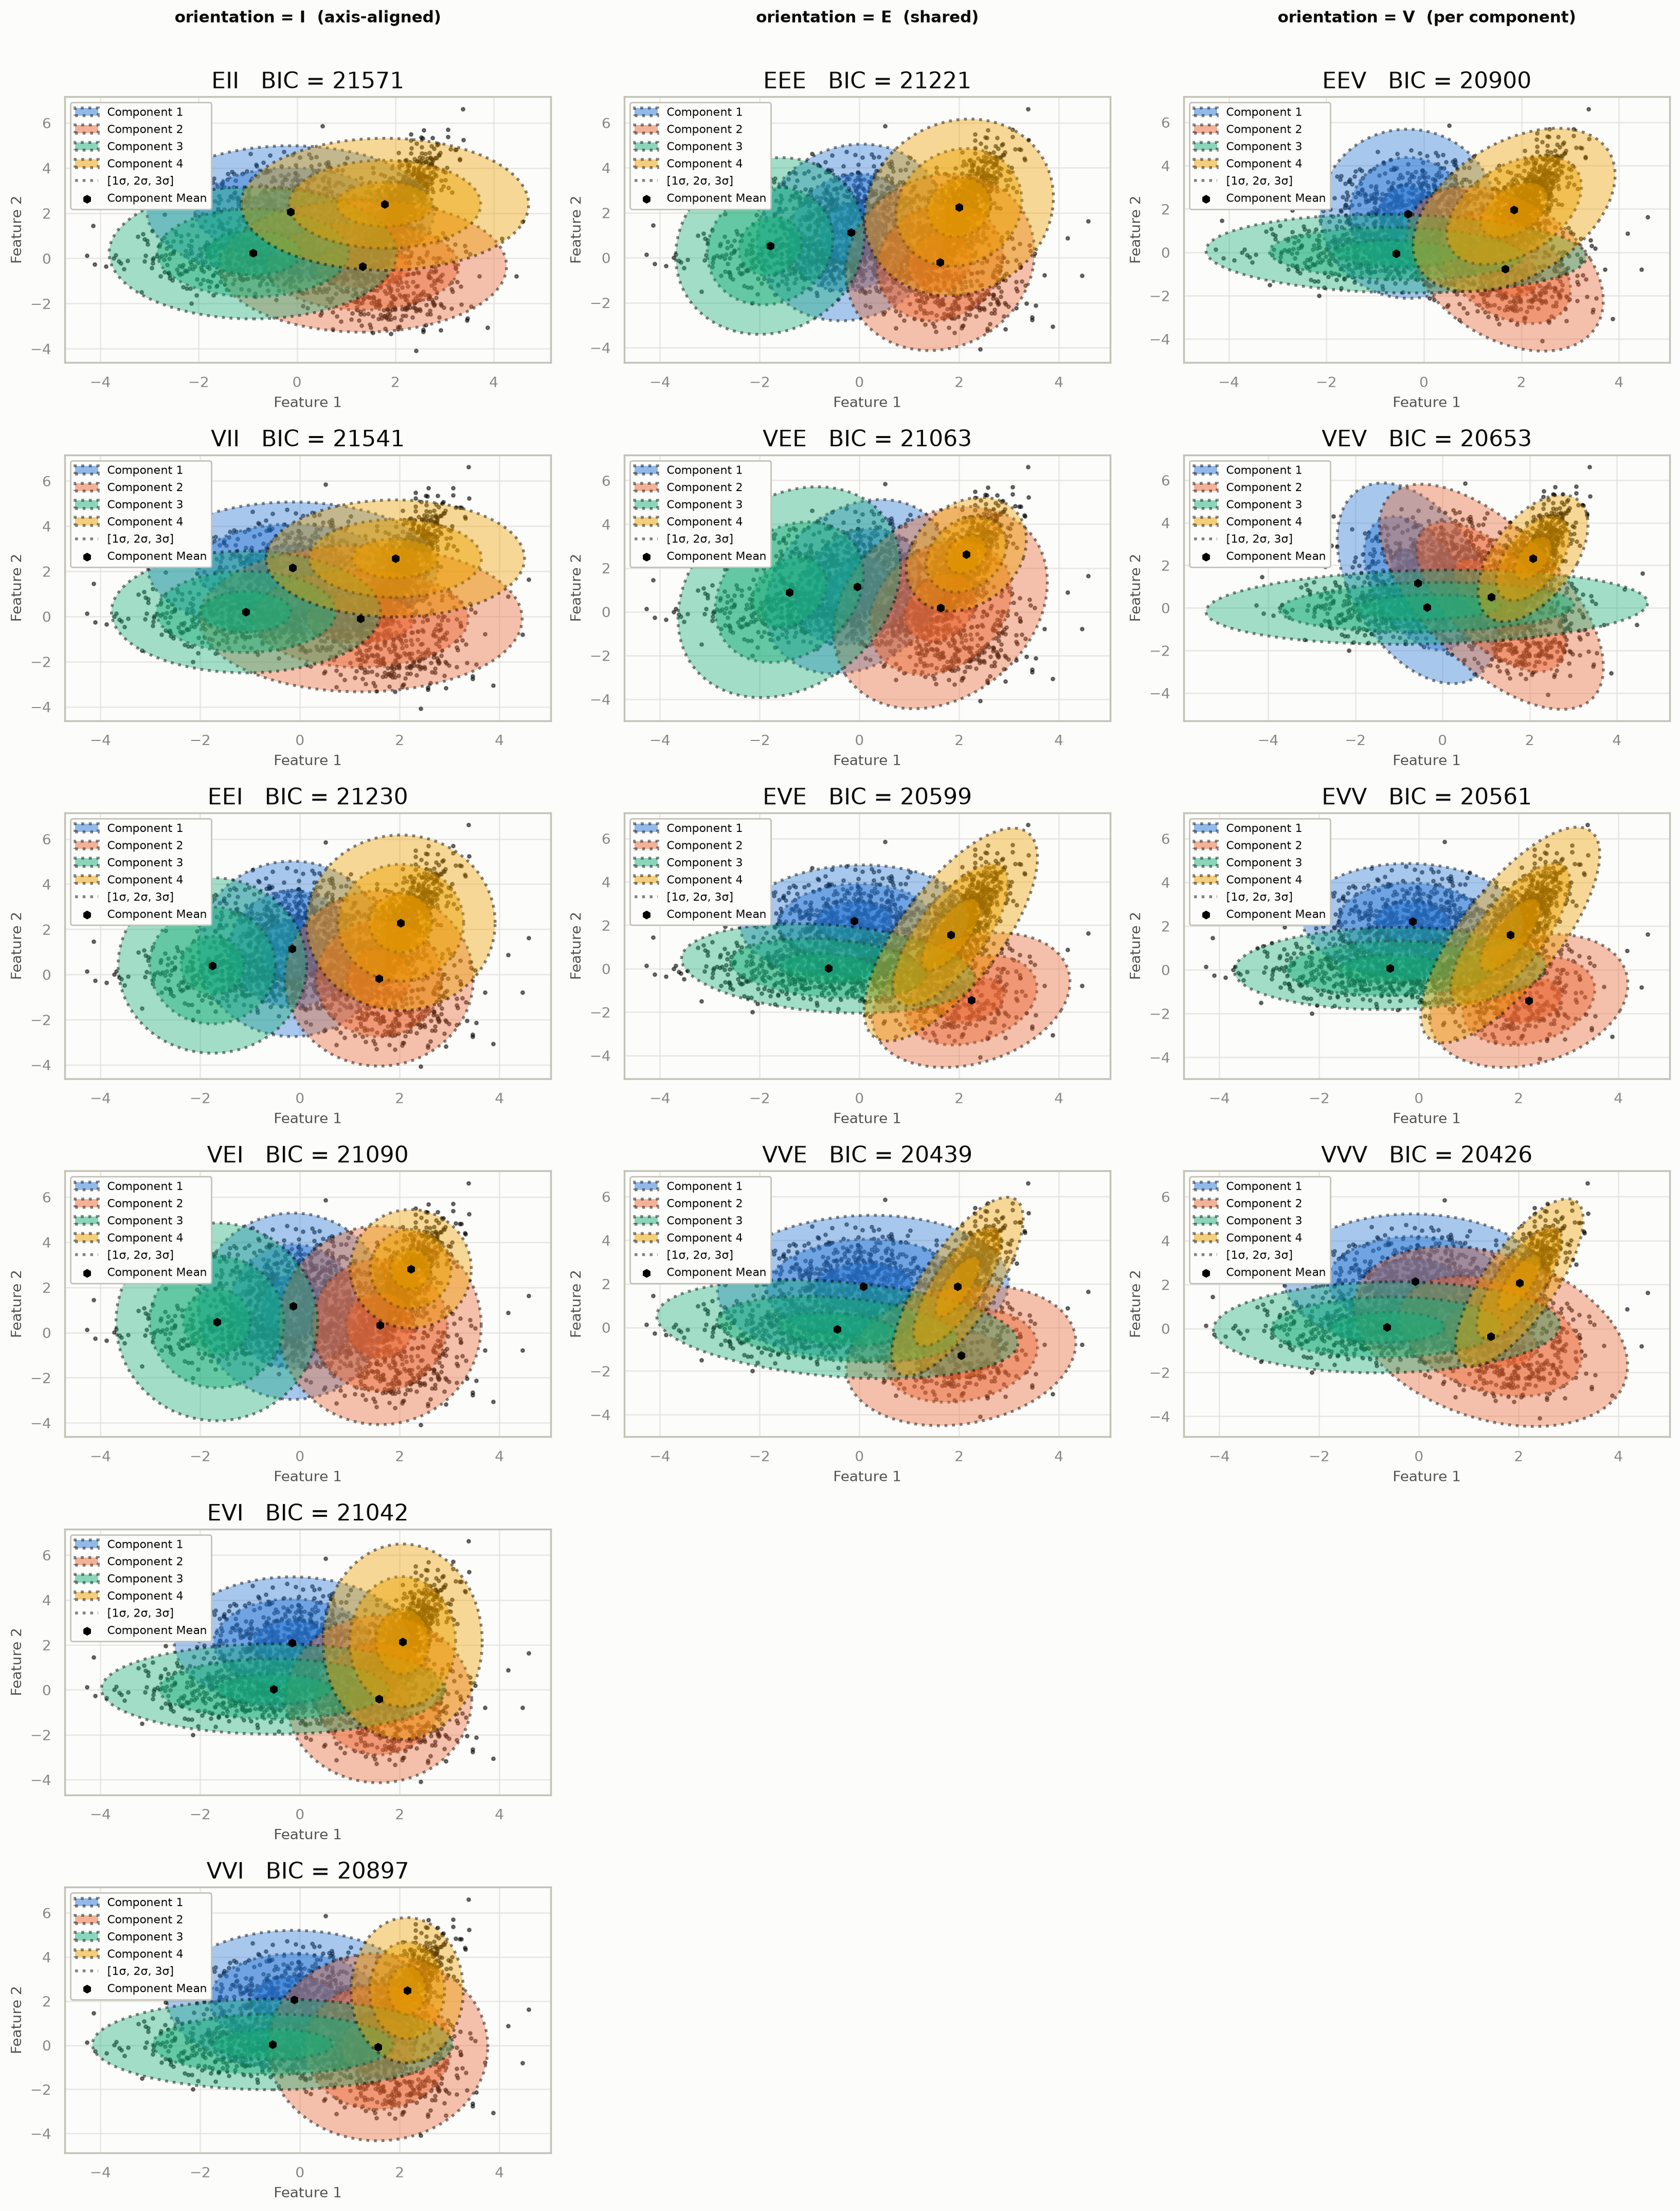

In [ ]:
columns = {'orientation = I  (axis-aligned)': ['EII', 'VII', 'EEI', 'VEI', 'EVI', 'VVI'], 'orientation = E  (shared)': ['EEE', 'VEE', 'EVE', 'VVE'], 'orientation = V  (per component)': ['EEV', 'VEV', 'EVV', 'VVV']}
fits = {}
_fig, _axs = plt.subplots(6, 3, figsize=dynamic_figsize(6, 3, base_width=5.5, base_height=3.6), dpi=100)
for col, (col_title, codes) in enumerate(columns.items()):
    for row in range(6):
        _ax = _axs[row, col]
        if row >= len(codes):
            _ax.axis('off')
            continue
        _code_name = codes[row]
        _gmm = GaussianMixture(n_components=K, covariance_type=_code_name, init_means='kmeans', random_state=SEED, device=device)
        _gmm.fit(X)
        fits[_code_name] = _gmm
        plot_gmm(X.cpu().numpy(), gmm=_gmm, ax=_ax, title=f'{_code_name}   BIC = {_gmm.bic(X):.0f}')
        if row == 0:
            _ax.annotate(col_title, xy=(0.5, 1.28), xycoords='axes fraction', ha='center', fontsize=11, weight='bold')
plt.tight_layout()
plt.gcf()

In [ ]:
summary = pd.DataFrame([
    {'code': c, 'alias': ALIASES.get(c, ''), 'log-likelihood': g.score(X) * n,
     'params': n_cov_params(c, K, d) + K * d + K - 1, 'BIC': g.bic(X), 'converged': g.converged_}
    for c, g in fits.items()
]).sort_values('BIC').reset_index(drop=True)
summary

,code,alias,log-likelihood,params,BIC,converged
0,VVV,full,-10120.952400,23,20426.051254,True
1,VVE,,-10139.345589,20,20438.818528,True
2,EVV,,-10200.408036,20,20560.943423,True
3,EVE,,-10231.463798,17,20599.035845,True
4,VEV,,-10246.428498,20,20652.984347,True
...,...,...,...,...,...,...
9,VEI,,-10480.948974,16,21089.999830,True
10,EEE,tied_full,-10554.605261,14,21221.299668,True
11,EEI,tied_diag,-10562.992429,13,21230.067637,True
12,VII,spherical,-10710.478512,15,21541.052537,True


## Selecting a covariance structure with `select_model`

With 14 candidates and an unknown number of components, nobody wants to pick by eye.
`select_model` fits every $(K,\text{covariance code})$ pair and ranks them by BIC (or AIC / ICL);
its default `covariance_types` is all 14 GPCM codes -- the mclust workflow.

### Iris petal measurements (2-D)

Petal length and width are the two iris features that most cleanly separate the three species --
small enough to sweep all 14 models for several $K$ quickly, and two-dimensional so that the winner
can be plotted directly.

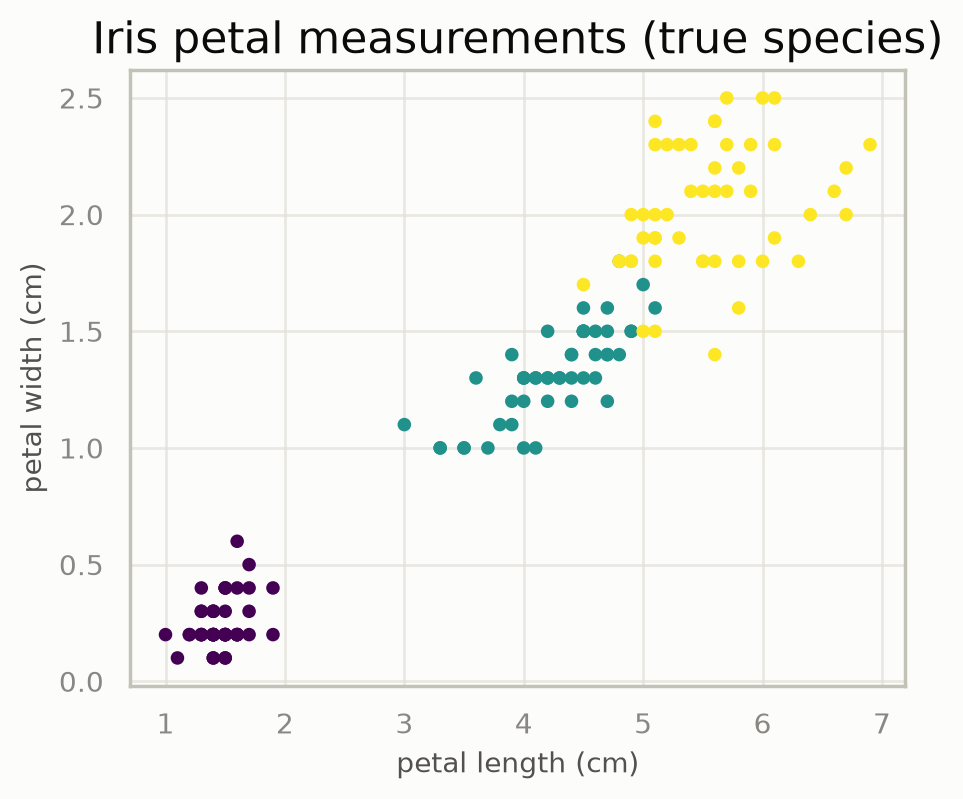

In [ ]:
iris = load_iris()
X_iris = torch.tensor(iris.data[:, [2, 3]], dtype=torch.float64)  # petal length, petal width

plt.figure(figsize=(5, 4))
plt.scatter(X_iris[:, 0], X_iris[:, 1], c=iris.target, cmap='viridis', s=15)
plt.xlabel('petal length (cm)')
plt.ylabel('petal width (cm)')
plt.title('Iris petal measurements (true species)')
plt.gcf()

In [ ]:
result_iris = select_model(
    X_iris, n_components=range(1, 6), criterion='bic',
    random_state=SEED, n_init=1, max_iter=200,
)

df_iris = result_iris.to_dataframe().sort_values('bic')
df_iris.head(10)

,n_components,covariance_type,bic,aic,icl,log_likelihood,converged
38,3,VVE,347.054572,301.895043,357.870257,-0.906317,True
52,4,VVE,354.818447,294.605741,370.829914,-0.848686,True
35,3,VEE,354.977602,315.839343,369.030811,-0.966131,True
41,3,VVV,355.957404,304.776604,368.395953,-0.902589,True
24,2,VVE,361.178482,331.072129,361.250534,-1.036907,True
49,4,VEE,361.414846,310.234046,376.459679,-0.920780,True
39,3,VEV,364.349955,319.190426,376.750136,-0.963968,True
27,2,VVV,364.579644,331.462656,364.637312,-1.031542,True
63,5,VEE,367.825669,304.602328,393.042544,-0.875341,True
55,4,VVV,369.243180,299.998569,405.605136,-0.846662,True


### BIC by model family and $K$

One line per covariance code, BIC against $K$ -- lower is better.

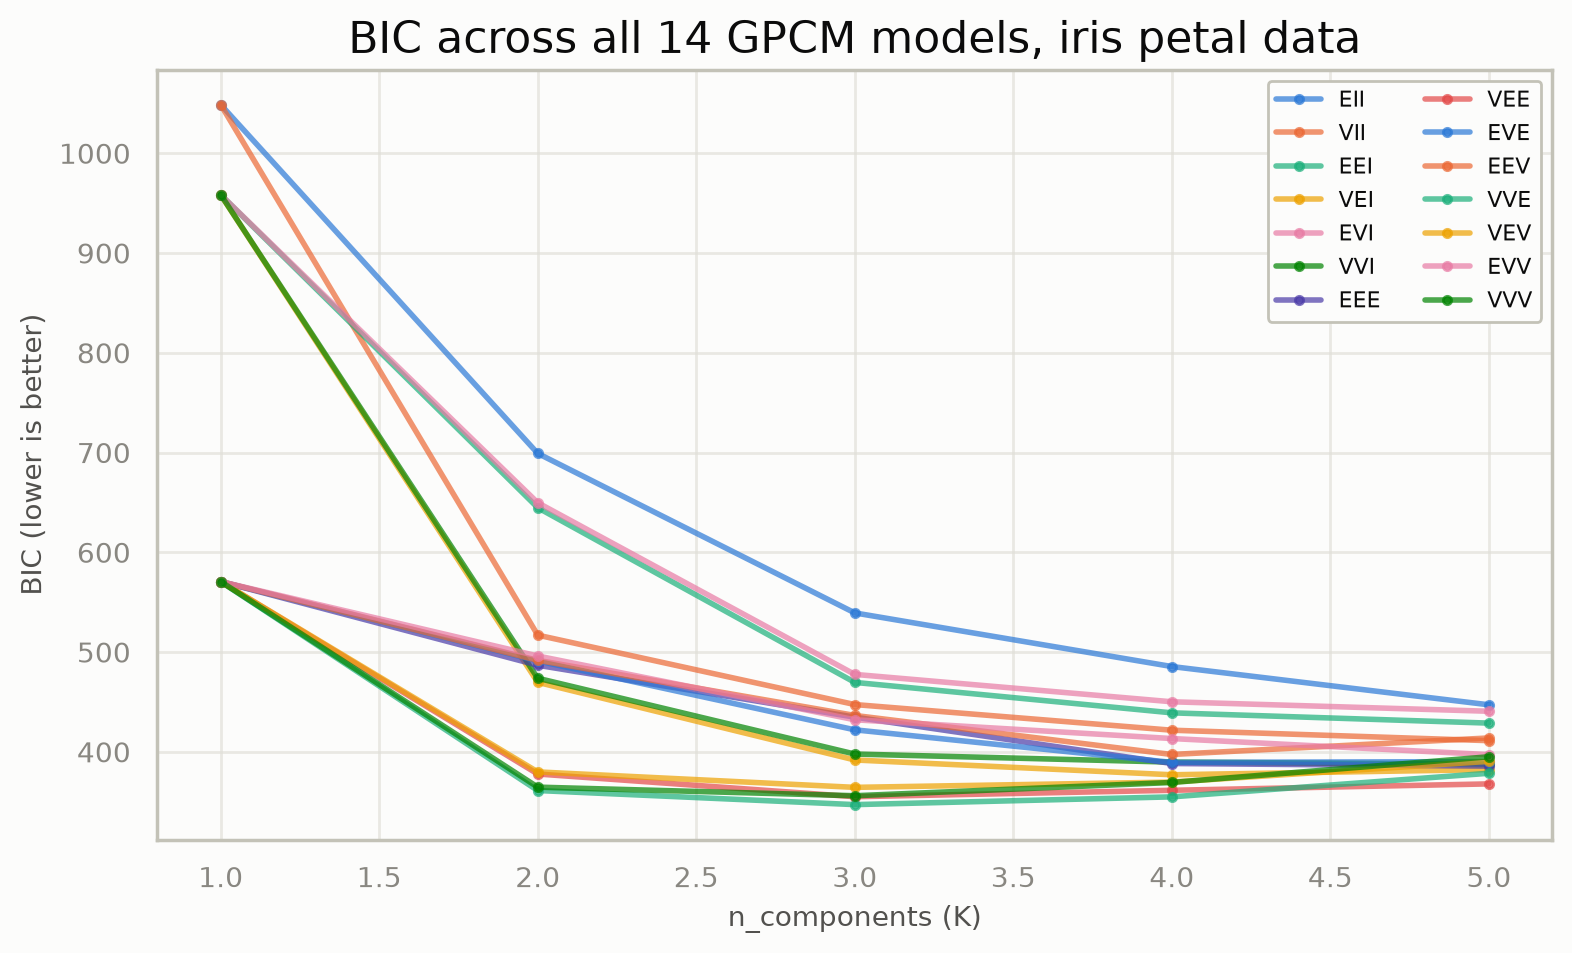

In [ ]:
plt.figure(figsize=(9, 5))
for _code_name in GPCM_CODES:
    sub = df_iris[df_iris['covariance_type'] == _code_name].sort_values('n_components')
    sub = sub.dropna(subset=['bic'])
    if len(sub) == 0:
        continue
    plt.plot(sub['n_components'], sub['bic'], marker='o', markersize=3, label=_code_name, alpha=0.7)
plt.xlabel('n_components (K)')
plt.ylabel('BIC (lower is better)')
plt.title('BIC across all 14 GPCM models, iris petal data')
plt.legend(ncol=2, fontsize=8)
plt.gcf()

In [ ]:
best = result_iris.best_
print(f'Winning model: {best.covariance_type_} (K={best.n_components}), BIC={best.bic(X_iris):.2f}')

Winning model: VVE (K=3), BIC=347.05


### The winning model's components, and why it won

The ellipses show what the selected structure looks like on the data. Because the winner carries a
decomposition (when it is one of the 8 new codes), `volume_`, `shape_` and `orientation_` say *what
kind* of parsimony the data supported -- shared or per-component size, elongation and rotation --
rather than merely that the model won.

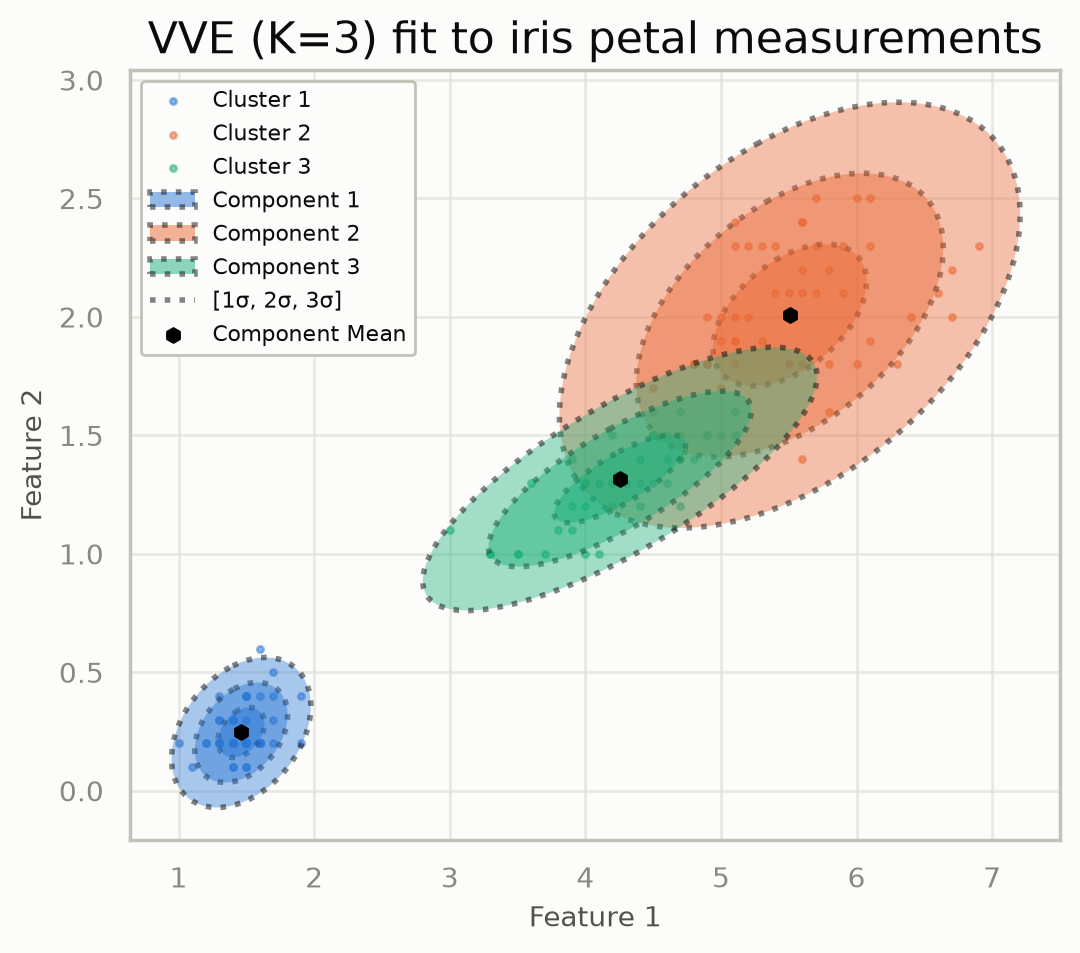

In [ ]:
plt.figure(figsize=(6, 5))
plot_gmm(X_iris.numpy(), gmm=best, true_labels=iris.target, color_by_cluster=True)
plt.title(f'{best.covariance_type_} (K={best.n_components}) fit to iris petal measurements')
plt.gcf()

In [ ]:
print('covariance_type_:', best.covariance_type_)
for _name in ('volume_', 'shape_', 'orientation_'):
    _value = getattr(best, _name)
    print(f'{_name}:', None if _value is None else _value.numpy().round(3))

covariance_type_: VVE
volume_: [0.017 0.149 0.057]
shape_: [[1.848 0.541]
 [2.315 0.432]
 [4.53  0.221]]
orientation_: [[ 0.954 -0.299]
 [ 0.299  0.954]]


### A 10-D latent-space-like dataset

Four clusters in 10 dimensions with deliberately varied covariance structure (different volumes,
some axis-aligned, some correlated and elongated) -- the situation a GPCM sweep is actually *for*:
no single covariance type is obviously right, and the full model spends $K\,d(d+1)/2=220$
covariance parameters at $K=4$.

In [ ]:
def make_latent_cluster(n, d, seed, volume, elongation=None, rotate=False):
    gen = torch.Generator().manual_seed(seed)
    base = torch.randn(n, d, generator=gen, dtype=torch.float64)
    scale = torch.ones(d, dtype=torch.float64)
    if elongation is not None:
        scale[: len(elongation)] = torch.tensor(elongation, dtype=torch.float64)
    X = base * scale.sqrt() * volume
    if rotate:
        Q, _ = torch.linalg.qr(torch.randn(d, d, generator=gen, dtype=torch.float64))
        X = X @ Q.T
    return X


torch.manual_seed(SEED)
d_latent = 10
latent_centers = torch.randn(4, d_latent, dtype=torch.float64) * 6
clusters = [
    make_latent_cluster(150, d_latent, seed=1, volume=1.0) + latent_centers[0],
    make_latent_cluster(150, d_latent, seed=2, volume=1.8) + latent_centers[1],
    make_latent_cluster(150, d_latent, seed=3, volume=1.0, elongation=[4, 4, 1, 1, 1, 1, 1, 1, 1, 1]) + latent_centers[2],
    make_latent_cluster(150, d_latent, seed=4, volume=1.0, elongation=[4, 4, 1, 1, 1, 1, 1, 1, 1, 1], rotate=True) + latent_centers[3],
]
X_latent = torch.cat(clusters, dim=0)
print(X_latent.shape)

torch.Size([600, 10])


In [ ]:
result_latent = select_model(
    X_latent, n_components=range(2, 6), criterion='bic',
    random_state=SEED, n_init=1, max_iter=100,
)

df_latent = result_latent.to_dataframe().sort_values('bic')
df_latent.head(10)

,n_components,covariance_type,bic,aic,icl,log_likelihood,converged
33,4,VVI,21907.941776,21542.996615,21907.941776,-17.814164,True
31,4,VEI,21916.855605,21670.627544,21916.855605,-17.965523,True
45,5,VEI,21983.885007,21684.893791,22065.915103,-17.957411,True
29,4,VII,21986.613174,21779.957480,21986.613174,-18.071631,True
38,4,VVE,21990.115924,21427.308929,21990.115924,-17.642757,True
47,5,VVI,22013.273801,21555.993117,22080.064980,-17.789994,True
43,5,VII,22056.274831,21796.855982,22140.860137,-18.065713,True
52,5,VVE,22083.877563,21428.735045,22120.824224,-17.608946,True
35,4,VEE,22113.303741,21669.213846,22113.303741,-17.889345,True
49,5,VEE,22180.738937,21683.885886,22254.015902,-17.881572,True


### BIC versus ICL at the winning $K$

BIC rewards fit and penalises parameters; ICL ([Model Selection tutorial](13_model_selection.ipynb))
additionally penalises overlap between clusters. Both criteria, compared across covariance
structures at the BIC-winning $K$.

In [ ]:
best_latent = result_latent.best_
winning_k = best_latent.n_components
print(f'Winning model: {best_latent.covariance_type_} (K={winning_k}), '
      f'BIC={best_latent.bic(X_latent):.2f}, ICL={best_latent.icl(X_latent):.2f}')

at_k = df_latent[df_latent['n_components'] == winning_k].dropna(subset=['bic', 'icl']).sort_values('bic')
at_k[['covariance_type', 'bic', 'icl', 'converged']].head(8)

Winning model: VVI (K=4), BIC=21907.94, ICL=21907.94


,covariance_type,bic,icl,converged
33,VVI,21907.941776,21907.941776,True
31,VEI,21916.855605,21916.855605,True
29,VII,21986.613174,21986.613174,True
38,VVE,21990.115924,21990.115924,True
35,VEE,22113.303741,22113.303741,True
30,EEI,22442.458830,22442.458830,True
32,EVI,22446.458565,22446.458565,True
28,EII,22474.234238,22474.234238,True


## Practical notes and limitations

- **Default.** `covariance_type='full'` (`VVV`) is the default and the most flexible; prefer a
  constrained model when $n_k$ is small relative to $d(d+1)/2$, or when you believe clusters share
  an orientation or a shape.
- **MLE only for the 8 new codes.** `mean_prior` / `covariance_prior` (MAP / NIW estimation) raise
  `NotImplementedError` for them -- a conjugate-prior derivation specific to each parameterisation is
  not provided. The six classic types still support the full prior machinery
  ([priors tutorial](09_priors.ipynb)); `weight_concentration_prior` works with all 14.
- **No Gibbs mode.** `n_components=None` (Dirichlet-process Gibbs sampling) is not available for
  the 8 new codes, as for `tied_*`: a covariance that couples components does not factor per
  component the way the collapsed sampler needs.
- **Iterative M-steps.** `VEI`, `VEE`, `VEV`, `EVE` and `VVE` alternate until the relative change in
  $J$ drops below `gpcm_tol` (default `1e-6`) or `gpcm_max_iter` (default `20`) sweeps are done; set
  `gpcm_tol` / `gpcm_max_iter` on the `GaussianMixture` to tighten or loosen this.
- **Initial covariances.** With `init_covariances='empirical'` or `'global'`, the starting
  covariances are projected onto the requested model (its constrained MLE); `'eye'` / `'random'`
  simply start from identity / random matrices.
- **`reg_covar`** is added to the *assembled* covariances, not to the decomposition, so `volume_`,
  `shape_` and `orientation_` describe the unregularised fit.

## Summary

- Every covariance type is the same M-step objective $J=\sum_k[n_k\log|\Sigma_k|+\mathrm{tr}(\Sigma_k^{-1}W_k)]$
  minimised over a different feasible set; the M-step only needs the sufficient statistics $n_k$ and $W_k$.
- The six classic types have simple closed forms (pooled for the `tied_` versions), verified here against
  `GaussianMixture`'s converged fits.
- The GPCM family writes $\Sigma_k=\lambda_kD_kA_kD_k^{\top}$ and lets volume, shape and orientation each be equal,
  varying or (for shape/orientation) the identity -- 14 models whose parameter counts add up factor by factor.
- Three of the new models have closed-form M-steps, three alternate closed-form sub-steps, and the two with a
  shared orientation and varying shape (`EVE`, `VVE`) need a numerical orthogonal-manifold step -- all matching an
  independent brute-force minimiser.
- `select_model` searches all 14 structures and the number of components together, and
  `volume_` / `shape_` / `orientation_` explain what the winning structure is.

**Next:** [13 -- Model Selection](13_model_selection.ipynb) for BIC / AIC / ICL in depth,
[09 -- Priors](09_priors.ipynb) for regularising covariance estimates (classic types), and the
[GPCM user guide](../user-guide/gpcm-covariance-models.md) as a reference.